In [162]:
# Author: Rishab
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path
import re

# project root = nearest folder above the notebook that holds clean/ and raw/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'clean').is_dir() and (p / 'raw').is_dir())
CLEAN = ROOT / 'clean' / 'election_results'
ACS = ROOT / 'raw' / 'demographics' / 'acs5'

panel = pd.read_csv(CLEAN / 'ohio_county_panel.csv', dtype={'county_fips': int})
races = pd.read_csv(CLEAN / 'senate_races.csv')

def nw(col):
    return panel[col] / panel[col].mean()

print(panel.shape, races.shape)
pd.set_option('display.max_rows', None)


(88, 42) (362, 15)


In [163]:
panel.info()

<class 'pandas.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 42 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   county_fips      88 non-null     int64  
 1   county_name      88 non-null     str    
 2   dem2p_pres_2000  88 non-null     float64
 3   dem2p_pres_2004  88 non-null     float64
 4   dem2p_pres_2008  88 non-null     float64
 5   dem2p_pres_2012  88 non-null     float64
 6   dem2p_pres_2016  88 non-null     float64
 7   dem2p_pres_2020  88 non-null     float64
 8   dem2p_pres_2024  88 non-null     float64
 9   votes_pres_2000  88 non-null     float64
 10  votes_pres_2004  88 non-null     float64
 11  votes_pres_2008  88 non-null     float64
 12  votes_pres_2012  88 non-null     float64
 13  votes_pres_2016  88 non-null     float64
 14  votes_pres_2020  88 non-null     float64
 15  votes_pres_2024  88 non-null     float64
 16  dem2p_sen_2004   88 non-null     float64
 17  votes_sen_2004   88 non-null 

   county_name  dem2p_pres_2024  votes_pres_2024  dem2p_sen_2024  \
24    FRANKLIN         0.643476         591348.0        0.674220   
17    CUYAHOGA         0.658534         571548.0        0.692326   
30    HAMILTON         0.575168         405725.0        0.598012   
76      SUMMIT         0.535242         270915.0        0.574295   
56  MONTGOMERY         0.502380         252333.0        0.537358   
47       LUCAS         0.563380         188718.0        0.597709   
75       STARK         0.389389         182568.0        0.431547   
8       BUTLER         0.367476         181544.0        0.399196   
46      LORAIN         0.471144         157504.0        0.524982   
82      WARREN         0.340865         138260.0        0.367883   
20    DELAWARE         0.466727         132105.0        0.492203   
42        LAKE         0.427634         127408.0        0.475600   
12    CLERMONT         0.319469         113094.0        0.348884   
49    MAHONING         0.452572         111885.0

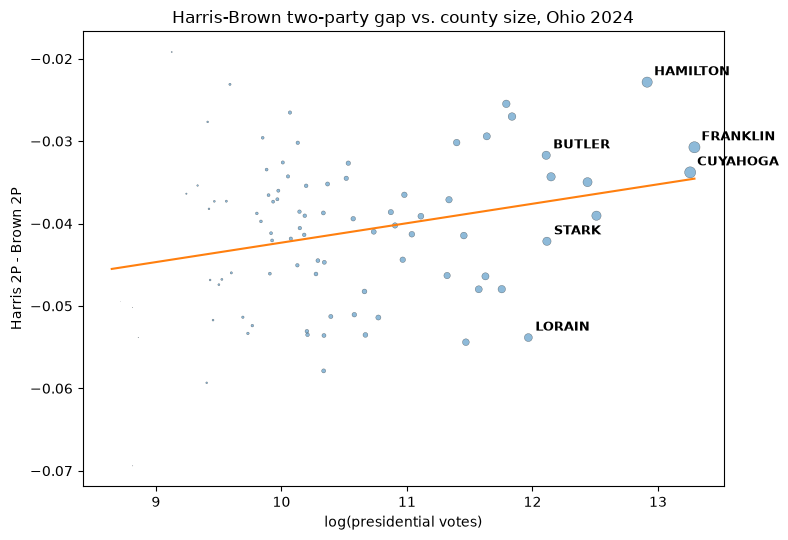

In [164]:
print(panel[['county_name', 'dem2p_pres_2024', 'votes_pres_2024','dem2p_sen_2024', 'votes_sen_2024']].sort_values(by = 'votes_sen_2024', ascending=False))

d = panel.assign(gap=panel.dem2p_pres_2024 - panel.dem2p_sen_2024,
                 logv=np.log(panel.votes_pres_2024))
ols = smf.ols('gap ~ logv', d).fit()
print(ols.summary())

fig, ax = plt.subplots(figsize=(8, 5.5))

big = ['FRANKLIN','CUYAHOGA','HAMILTON','STARK','BUTLER','LORAIN']
labeled = d[d.county_name.str.upper().str.contains('|'.join(big), na=False)]
print(labeled.county_name.tolist())

ax.scatter(d.logv, d.gap, s=3*(d.logv - d.logv.min())**2,
           alpha=0.5, edgecolor='k', linewidth=0.3)

xs = np.linspace(d.logv.min(), d.logv.max(), 100)
ax.plot(xs, ols.predict({'logv': xs}), 'C1', label='OLS')

for _, r in labeled.iterrows():
    ax.annotate(r.county_name, (r.logv, r.gap), fontsize=9, fontweight='bold',
                xytext=(5,5), textcoords='offset points')

ax.set(xlabel='log(presidential votes)', ylabel='Harris 2P - Brown 2P',
       title='Harris-Brown two-party gap vs. county size, Ohio 2024')
fig.tight_layout()


In [165]:
# A. Brown vs lagged presidential baseline, one election at a time
# OLS throughout: every county counts the same, so the estimand is the typical
# COUNTY. (The weighted version would make it the typical voter -- see the
# OLS/WLS comparison in the cross-state cell below.)
SPECS = {2012: ('dem2p_sen_2012', 'dem2p_pres_2008', 'votes_sen_2012'),
         2018: ('dem2p_sen_2018', 'dem2p_pres_2016', 'votes_sen_2018'),
         2024: ('dem2p_sen_2024', 'dem2p_pres_2020', 'votes_sen_2024')}

lag_fits = {}          # renamed from `fits`: the cross-state cell below also
rows = []              # built a dict called `fits`, which silently clobbered this one
for yr, (y, x, w) in SPECS.items():
    m = smf.ols(f'{y} ~ {x}', data=panel).fit()
    lag_fits[yr] = m
    panel[f'resid_{yr}'] = m.resid
    sw = (panel[y] * panel[w]).sum() / panel[w].sum()   # statewide share is
    rows.append({'year': yr, 'slope': m.params[x],      # still vote-weighted:
                 'intercept': m.params['Intercept'],    # that is an aggregation,
                 'r2': m.rsquared, 'statewide_dem2p': sw})   # not an estimator

baseline = pd.DataFrame(rows).set_index('year').round(4)
baseline


,slope,intercept,r2,statewide_dem2p
year,,,,
2012,1.1085,-0.0523,0.9381,0.5315
2018,0.8837,0.1408,0.9230,0.5341
2024,0.9846,0.0334,0.9939,0.4813


             2012    2024
OLS slope -0.0034  0.0024


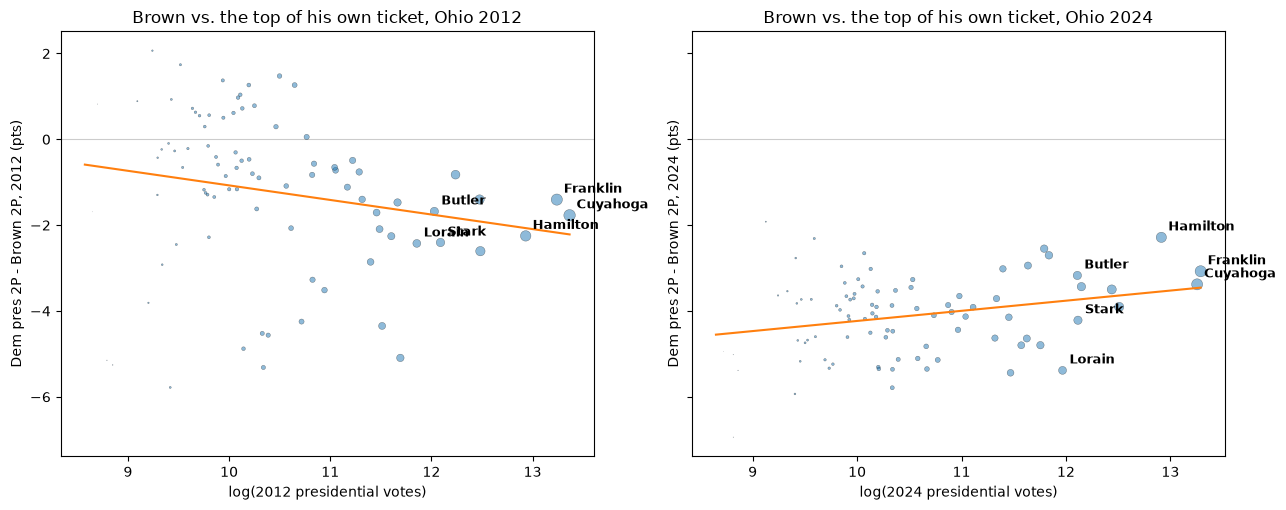

In [166]:
def gap_plot(yr, ax=None):
    g = panel.assign(gap=panel[f'dem2p_pres_{yr}'] - panel[f'dem2p_sen_{yr}'],
                     logv=np.log(panel[f'votes_pres_{yr}']))
    ols = smf.ols('gap ~ logv', g).fit()
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5.5))
    ax.scatter(g.logv, g.gap * 100, s=3*(g.logv - g.logv.min())**2,
               alpha=.5, edgecolor='k', linewidth=.3)
    xs = np.linspace(g.logv.min(), g.logv.max(), 100)
    ax.plot(xs, ols.predict({'logv': xs}) * 100, 'C1', label='OLS')
    big = ['FRANKLIN','CUYAHOGA','HAMILTON','STARK','BUTLER','LORAIN']
    for _, r in g[g.county_name.str.upper().str.contains('|'.join(big), na=False)].iterrows():
        ax.annotate(r.county_name.title(), (r.logv, r.gap * 100), fontsize=9,
                    fontweight='bold', xytext=(5,5), textcoords='offset points')
    ax.axhline(0, color='#ccc', lw=.8, zorder=0)
    ax.set(xlabel=f'log({yr} presidential votes)',
           ylabel=f'Dem pres 2P - Brown 2P, {yr} (pts)',
           title=f'Brown vs. the top of his own ticket, Ohio {yr}')
    
    return ols

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
o12 = gap_plot(2012, axes[0])
o24 = gap_plot(2024, axes[1])
fig.tight_layout()
print(pd.DataFrame({'2012': [o12.params.logv], '2024': [o24.params.logv]},
                   index=['OLS slope']).round(4))


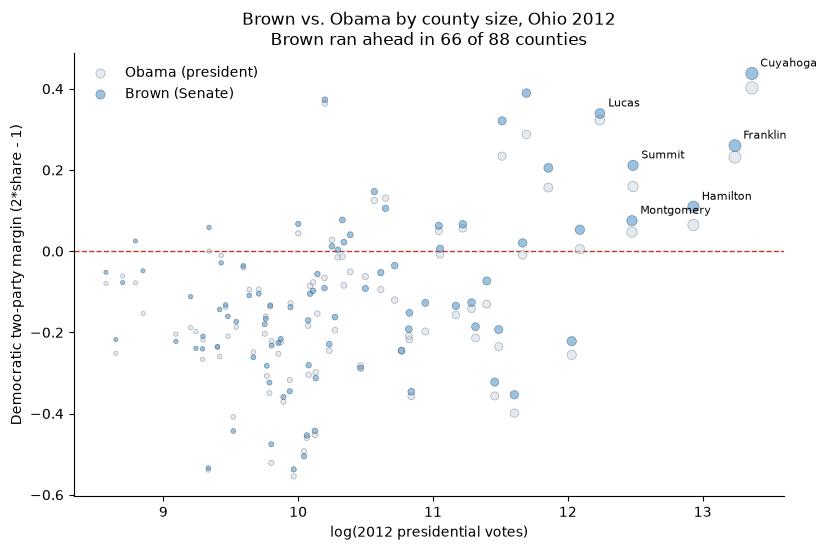

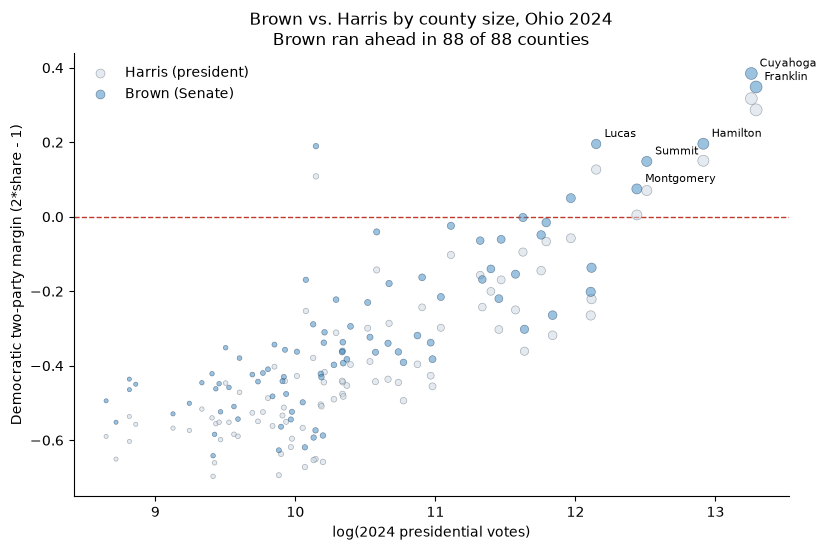

In [167]:
# One figure per year: the presidential candidate and Brown, by county size.
# x = log of that year's presidential turnout, y = Dem two-party MARGIN
# (2*share - 1), so 0 is a tie.
for yr, pres_name in [(2012, 'Obama'), (2024, 'Harris')]:
    g = panel.assign(logv=np.log(panel[f'votes_pres_{yr}']),
                     pres=2 * panel[f'dem2p_pres_{yr}'] - 1,
                     sen=2 * panel[f'dem2p_sen_{yr}'] - 1)
    fig, ax = plt.subplots(figsize=(8.4, 5.6))
    s = 3 * (g.logv - g.logv.min()) ** 2 + 9     # +9 keeps the smallest visible
    ax.scatter(g.logv, g.pres, s=s, alpha=.55, facecolor='#cfd9e2',
               edgecolor='#5b6b7a', linewidth=.45,
               label=f'{pres_name} (president)')
    ax.scatter(g.logv, g.sen, s=s, alpha=.55, facecolor='#4a90c4',
               edgecolor='#1b3a5c', linewidth=.45, label='Brown (Senate)')
    for _, r in g.nlargest(6, f'votes_pres_{yr}').iterrows():
        ax.annotate(r.county_name.title(), (r.logv, r.sen), fontsize=8,
                    xytext=(6, 5), textcoords='offset points')
    ax.axhline(0, color='#c0392b', lw=1, ls='--', zorder=0)
    # how often did Brown actually finish above the top of the ticket?
    ahead = int((g.sen > g.pres).sum())
    ax.set(xlabel=f'log({yr} presidential votes)',
           ylabel='Democratic two-party margin (2*share - 1)',
           title=f'Brown vs. {pres_name} by county size, Ohio {yr}\n'
                 f'Brown ran ahead in {ahead} of {len(g)} counties')
    ax.legend(frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    plt.show()


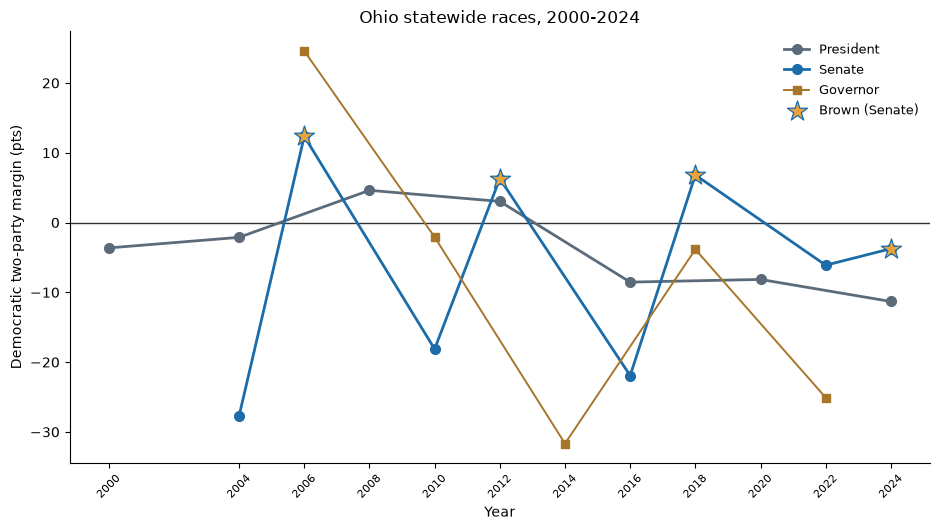

In [168]:
# Statewide Democratic two-party margin, every race in the panel.
def statewide(off, yr):
    s, v = panel[f'dem2p_{off}_{yr}'], panel[f'votes_{off}_{yr}']
    return (2 * (s * v).sum() / v.sum() - 1) * 100

rows = []
for c in panel.columns:
    m = re.fullmatch(r'dem2p_(pres|sen|gov)_(\d{4})', c)
    if m and f'votes_{m.group(1)}_{m.group(2)}' in panel.columns:
        rows.append({'office': m.group(1), 'year': int(m.group(2)),
                     'margin': statewide(m.group(1), int(m.group(2)))})
mg = pd.DataFrame(rows).sort_values('year')
BROWN = [2006, 2012, 2018, 2024]

fig, ax = plt.subplots(figsize=(9.5, 5.4))
style = {'pres': ('President', '#5b6b7a', 'o', 2.0, 7),
         'sen':  ('Senate',    '#1b6ca8', 'o', 2.0, 7),
         'gov':  ('Governor',  '#a8762a', 's', 1.4, 6)}
for off, (lab, col, mk, lw, ms) in style.items():
    dd = mg[mg.office == off]
    ax.plot(dd.year, dd.margin, mk + '-', color=col, lw=lw, ms=ms, label=lab)

bs = mg[(mg.office == 'sen') & mg.year.isin(BROWN)]
ax.scatter(bs.year, bs.margin, s=230, marker='*', color='#e8a33d',
           edgecolor='#1b6ca8', linewidth=.9, zorder=5, label='Brown (Senate)')

ax.axhline(0, color='#333', lw=1, zorder=0)
ax.set_xticks(sorted(mg.year.unique()))
ax.tick_params(axis='x', labelrotation=45, labelsize=8)
ax.set(xlabel='Year', ylabel='Democratic two-party margin (pts)',
       title='Ohio statewide races, 2000-2024')
ax.legend(frameon=False, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()


In [169]:
# =============================================================================
# CROSS-STATE BASELINE, BUILT UP ONE TERM AT A TIME
#
#   dem2p_sen_{s,t} = a + b*dem2p_pres_{s,tau(t)} + g*penalty_t
#                       + d*inc_{s,t} + p*brown_{s,t} + mu_s + u_{s,t}
#
# Unit of observation: one Senate race (state s, year t), 2004-2024.
# Estimated by OLS: every race counts the same, so the estimand is the typical
# RACE. A WLS/OLS comparison is printed at the bottom of this cell, because the
# choice is not innocuous here -- it changes the incumbency coefficient by half
# and costs the Brown premium its significance.
# =============================================================================

# --- variables already present in senate_races.csv ---------------------------
#   dem2p_sen   Dem two-party Senate share in state s, year t      (dependent)
#   dem2p_pres  Dem two-party presidential share in state s at the most
#               recent presidential election tau(t); the column pres_year
#               records tau(t) itself
#   penalty     +1 if the sitting president is a DEMOCRAT in a midterm year,
#               -1 if a REPUBLICAN, 0 in presidential years. Because the
#               dependent variable is the DEM share, g is expected negative.
#   votes_sen   total two-party Senate votes (used only for weighting checks
#               and for vote-weighted aggregation, not by the OLS fits)
#   inc_status  five categories: dem_elected, dem_appointed, rep_elected,
#               rep_appointed, open
#   state_po    two-letter state code, supplies the fixed effect mu_s
#
# --- variables DEFINED HERE --------------------------------------------------
# inc: symmetric incumbency. Imposes that incumbency is worth the same to
# both parties, which buys power: the four-category version leaves only
# 6 rep_appointed races and cannot identify them (p = 0.43).
INC_MAP = {'dem_elected': 1, 'dem_appointed': 1,
           'rep_elected': -1, 'rep_appointed': -1, 'open': 0}
races['inc'] = races.inc_status.map(INC_MAP)

# brown: indicator for Sherrod Brown's own four Ohio races.
BROWN_YEARS = [2006, 2012, 2018, 2024]
races['brown'] = ((races.state_po == 'OH')
                  & races.year.isin(BROWN_YEARS)).astype(int)

# w: vote weight, normalised to mean 1. Used ONLY for the comparison at the
# bottom of this cell; the headline models are unweighted.
races['w'] = races.votes_sen / races.votes_sen.mean()

# --- the nested sequence -----------------------------------------------------
# Each model adds ONE term. Estimated jointly, not by residualising stage by
# stage: adding a regressor that is correlated with one already in the model
# changes the earlier coefficients (Frisch-Waugh-Lovell), and inc IS
# correlated with dem2p_pres because Dem incumbents sit in Dem-leaning states.
# Watch b move between M1 and M2 -- that movement is the omitted-variable bias
# that a stagewise residual regression would have left in place.
MODELS = {
    'M0 pres only'   : 'dem2p_sen ~ dem2p_pres',
    'M1 + penalty'   : 'dem2p_sen ~ dem2p_pres + penalty',
    'M2 + incumbency': 'dem2p_sen ~ dem2p_pres + penalty + inc',
    'M3 + brown'     : 'dem2p_sen ~ dem2p_pres + penalty + inc + brown',
    'M4 + state FE'  : 'dem2p_sen ~ dem2p_pres + penalty + inc + brown + C(state_po)',
}
nested = {k: smf.ols(f, races).fit() for k, f in MODELS.items()}   # renamed
                                     # from `fits` to stop clobbering cell A's

# --- coefficients with standard errors underneath ----------------------------
TERMS = ['Intercept', 'dem2p_pres', 'penalty', 'inc', 'brown']
LBL = {'Intercept': 'a  (intercept)', 'dem2p_pres': 'b  (lagged pres)',
       'penalty': 'g  (midterm penalty)', 'inc': 'd  (incumbency)',
       'brown': 'p  (Brown premium)'}

rows = []
for term in TERMS:
    rows.append([LBL[term]] + [f'{f.params[term]:+.4f}' if term in f.params else ''
                               for f in nested.values()])
    rows.append([''] + [f'({f.bse[term]:.4f})' if term in f.params else ''
                        for f in nested.values()])
rows.append(['R2'] + [f'{f.rsquared:.3f}' for f in nested.values()])
rows.append(['resid sd (sigma)'] + [f'{np.sqrt(f.mse_resid):.4f}' for f in nested.values()])
rows.append(['N'] + [f'{int(f.nobs)}' for f in nested.values()])

tab = pd.DataFrame(rows, columns=['term'] + list(nested)).set_index('term')
print('OLS. Standard errors in parentheses. Dependent variable: dem2p_sen.')
print(tab.to_string())

print('\np-values:')
for k in ['M2 + incumbency', 'M3 + brown', 'M4 + state FE']:
    f = nested[k]
    bits = [f'{t} p={f.pvalues[t]:.4f}' for t in ('inc', 'brown') if t in f.pvalues]
    print(f'  {k:18s} ' + '   '.join(bits))

# --- residuals as terms are added --------------------------------------------
# u_hat for Ohio specifically. The point: before state FE enter, Ohio's
# non-Brown races carry a large negative residual, and the brown dummy is
# forced to absorb that state-level drag before it can measure anything
# about Brown himself.
print('\nOhio residuals u_hat by model:')
oh_res = pd.DataFrame({k: f.resid[races.state_po == 'OH'] for k, f in nested.items()})
oh_res.insert(0, 'year', races.loc[races.state_po == 'OH', 'year'])
oh_res.insert(1, 'Brown', races.loc[races.state_po == 'OH', 'brown'].map({1: 'yes', 0: ''}))
print(oh_res.round(4).to_string(index=False))

print('\nMean Ohio residual, Brown races vs the rest:')
for k, f in nested.items():
    m = races.state_po == 'OH'
    rb = f.resid[m & (races.brown == 1)].mean()
    rn = f.resid[m & (races.brown == 0)].mean()
    print(f'  {k:18s} Brown {rb:+.4f}   non-Brown {rn:+.4f}   difference {rb-rn:+.4f}')

m_full = nested['M4 + state FE']
print('\n--- full summary of M4 (state dummies suppressed) ---')
print(m_full.summary2().tables[1].loc[TERMS].round(4).to_string())

# =============================================================================
# OLS vs WLS: does the estimator choice matter? Yes, in two places.
# =============================================================================
print('\n--- OLS vs WLS (weights = votes_sen) ---')
cmp_rows = []
for k, f in MODELS.items():
    o, w = nested[k], smf.wls(f, races, weights=races.w).fit()
    for t in ['dem2p_pres', 'penalty', 'inc', 'brown']:
        if t in o.params:
            cmp_rows.append({'model': k, 'term': t,
                             'OLS': f'{o.params[t]:+.4f} ({o.bse[t]:.4f})',
                             'WLS': f'{w.params[t]:+.4f} ({w.bse[t]:.4f})',
                             'p OLS': round(o.pvalues[t], 4),
                             'p WLS': round(w.pvalues[t], 4)})
print(pd.DataFrame(cmp_rows).set_index(['model', 'term']).to_string())
print("""
Two differences matter and both should be reported:
  inc    OLS +0.0494 vs WLS +0.0327. Incumbency is worth more in small states,
         which OLS weights equally and WLS discounts.
  brown  OLS +0.0395 (p = 0.41) vs WLS +0.0594 (p = 0.03). The premium is
         identified off ONE large state, so down-weighting Ohio to 1/50 both
         shrinks the estimate and nearly doubles its standard error. Under OLS
         the Brown premium is NOT statistically distinguishable from zero.""")


OLS. Standard errors in parentheses. Dependent variable: dem2p_sen.
                     M0 pres only M1 + penalty M2 + incumbency M3 + brown M4 + state FE
term                                                                                   
a  (intercept)            +0.0429      +0.0415         +0.1791    +0.1795       +0.3721
                         (0.0244)     (0.0231)        (0.0230)   (0.0230)      (0.0538)
b  (lagged pres)          +0.9243      +0.9370         +0.6481    +0.6475       +0.1918
                         (0.0492)     (0.0465)        (0.0469)   (0.0470)      (0.1196)
g  (midterm penalty)                   -0.0460         -0.0367    -0.0369       -0.0330
                                      (0.0070)        (0.0060)   (0.0060)      (0.0061)
d  (incumbency)                                        +0.0636    +0.0637       +0.0494
                                                      (0.0055)   (0.0055)      (0.0056)
p  (Brown premium)                                  

State fixed effects, recentred on the unweighted mean (base state in the regression was AK; its se is NaN because it is the reference, not because it is missing).
Ohio: mu_OH = -0.0454 share pts (-9.1 margin pts), rank 14 of 50 from the bottom.
      mu_s      se
ME -0.1751  0.0423
WY -0.1564  0.0389
UT -0.1186  0.0379
ID -0.0823  0.0393
KS -0.0820  0.0386
LA -0.0817  0.0373
OK -0.0777  0.0359
AL -0.0771  0.0386
TN -0.0768  0.0374
SD -0.0559  0.0386
AR -0.0540  0.0406
NE -0.0534  0.0373
ND -0.0486  0.0362
OH -0.0454  0.0448
MS -0.0404  0.0367
SC -0.0300  0.0366
AK -0.0273     NaN
IA -0.0266  0.0395
AZ -0.0226  0.0368
FL -0.0222  0.0385
TX -0.0187  0.0379
IN -0.0176  0.0378
MO -0.0089  0.0371
NH -0.0002  0.0401
GA  0.0089  0.0371
NV  0.0116  0.0396
WV  0.0141  0.0364
MT  0.0159  0.0376
KY  0.0160  0.0373
WA  0.0182  0.0428
WI  0.0184  0.0397
PA  0.0192  0.0396
MI  0.0241  0.0411
NJ  0.0272  0.0432
NC  0.0301  0.0385
CO  0.0341  0.0401
VA  0.0383  0.0403
MN  0.0398  0.0401
NM  0.0539  0.

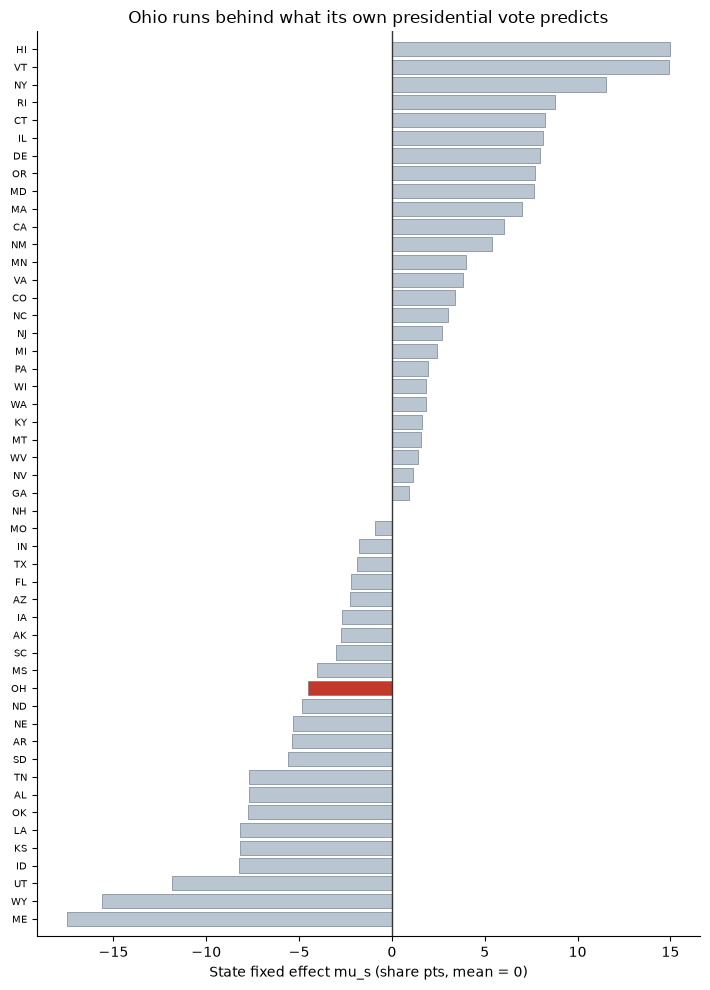

In [170]:
# =============================================================================
# THE STATE FIXED EFFECTS mu_s FROM M4
#
# statsmodels reports each dummy relative to the omitted base state
# (alphabetically first). That base is arbitrary, so recentre on the mean.
# With OLS the natural centre is the UNWEIGHTED mean across states, matching
# the estimator. Note the centring choice has no effect on any forecast: it
# shifts mu_s and the intercept by equal and opposite amounts.
# =============================================================================
fe = m_full.params.filter(like='C(state_po)')
fe.index = [i.split('T.')[1].rstrip(']') for i in fe.index]   # tidy the labels
fe_se = m_full.bse.filter(like='C(state_po)')
fe_se.index = fe.index

BASE_STATE = sorted(set(races.state_po) - set(fe.index))[0]   # the omitted state
fe = pd.concat([pd.Series({BASE_STATE: 0.0}), fe])            # put it back at 0
fe_se = pd.concat([pd.Series({BASE_STATE: np.nan}), fe_se])
fe = fe - fe.mean()                                           # unweighted centre

mu = pd.DataFrame({'mu_s': fe, 'se': fe_se}).sort_values('mu_s')
print(f'State fixed effects, recentred on the unweighted mean '
      f'(base state in the regression was {BASE_STATE}; its se is NaN because '
      f'it is the reference, not because it is missing).')
print(f'Ohio: mu_OH = {mu.loc["OH", "mu_s"]:+.4f} share pts '
      f'({mu.loc["OH", "mu_s"]*200:+.1f} margin pts), '
      f'rank {list(mu.index).index("OH") + 1} of {len(mu)} from the bottom.')
print(mu.round(4).to_string())

fig, ax = plt.subplots(figsize=(7.2, 10))
colors = ['#c0392b' if s == 'OH' else '#b9c6d2' for s in mu.index]
ax.barh(np.arange(len(mu)), mu.mu_s * 100, color=colors,
        edgecolor='#5b6b7a', linewidth=.4)
ax.set_yticks(np.arange(len(mu)))
ax.set_yticklabels(mu.index, fontsize=7.5)
ax.axvline(0, color='#333', lw=1)
ax.set_ylim(-1, len(mu))
ax.set(xlabel='State fixed effect mu_s (share pts, mean = 0)',
       title='Ohio runs behind what its own presidential vote predicts')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()


In [171]:
# =============================================================================
# SPECIFICATION TABLE: build-up, state FE on/off, Brown premium on/off
# Incumbency is kept in every column from (3) onward, as it is the term the
# 2026 forecast is most sensitive to.
# =============================================================================
# --- derived race variables, repeated from the build-up cell above so that
# --- this cell runs standalone (re-running them is harmless and idempotent).
if 'inc' not in races.columns or 'brown' not in races.columns:
    INC_MAP = {'dem_elected': 1, 'dem_appointed': 1,
               'rep_elected': -1, 'rep_appointed': -1, 'open': 0}
    races['inc'] = races.inc_status.map(INC_MAP)
    races['brown'] = ((races.state_po == 'OH')
                      & races.year.isin([2006, 2012, 2018, 2024])).astype(int)
    races['w'] = races.votes_sen / races.votes_sen.mean()

# Ohio's 2024 two-party presidential share: the single input every forecast
# below is built on. Vote-weighted across the 88 counties.
OH_PRES_2024 = ((panel.dem2p_pres_2024 * panel.votes_pres_2024).sum()
                / panel.votes_pres_2024.sum())
print(f'OH 2024 two-party presidential (D): {OH_PRES_2024:.4f}\n')

GRID = {
 '(1) pres':            'dem2p_sen ~ dem2p_pres',
 '(2) +penalty':        'dem2p_sen ~ dem2p_pres + penalty',
 '(3) +incumb':         'dem2p_sen ~ dem2p_pres + penalty + inc',
 '(4) +brown':          'dem2p_sen ~ dem2p_pres + penalty + inc + brown',
 '(5) +FE, no brown':   'dem2p_sen ~ dem2p_pres + penalty + inc + C(state_po)',
 '(6) +FE +brown':      'dem2p_sen ~ dem2p_pres + penalty + inc + brown + C(state_po)',
}
grid = {k: smf.ols(f, races).fit() for k, f in GRID.items()}

ROWS = [('dem2p_pres', 'b   lagged pres'), ('penalty', 'g   midterm penalty'),
        ('inc', 'd   incumbency'), ('brown', 'p   Brown premium')]

def ohio_share(fit, inc_val):
    """2026 Ohio two-party share implied by `fit`, given an incumbency coding.
    Uses the RAW Ohio dummy (0 when the model has no state FE, or when Ohio is
    the omitted base), so the arithmetic is independent of the reference state."""
    b = fit.params
    return (b['Intercept'] + b['dem2p_pres'] * OH_PRES_2024
            + b.get('C(state_po)[T.OH]', 0.0)
            + b.get('penalty', 0.0) * (-1)       # column (1) has neither
            + b.get('inc', 0.0) * inc_val        # penalty nor inc
            + b.get('brown', 0.0))

rows = []
for term, lab in ROWS:
    rows.append([lab] + [f'{f.params[term]:+.4f}' if term in f.params else '--'
                         for f in grid.values()])
    rows.append(['']  + [f'({f.bse[term]:.4f})' if term in f.params else ''
                         for f in grid.values()])
    rows.append(['']  + [f'p={f.pvalues[term]:.3f}' if term in f.params else ''
                         for f in grid.values()])
rows.append(['state FE'] + ['yes' if 'C(state_po)' in f.model.formula else 'no'
                            for f in grid.values()])
rows.append(['R2'] + [f'{f.rsquared:.3f}' for f in grid.values()])
rows.append(['sigma'] + [f'{np.sqrt(f.mse_resid):.4f}' for f in grid.values()])
rows.append(['mu_OH (raw)'] + [f'{f.params.get("C(state_po)[T.OH]", float("nan")):+.4f}'
                               if 'C(state_po)' in f.model.formula else '--'
                               for f in grid.values()])
rows.append(['--- 2026 forecast ---'] + [''] * len(grid))
for iv, lab in [(-1, 'Husted incumbent'), (0, 'Husted open seat')]:
    rows.append([f'  share, {lab}'] + [f'{ohio_share(f, iv):.4f}' for f in grid.values()])
    rows.append([f'  margin, {lab}']
                + [f'{(2*ohio_share(f, iv)-1)*100:+.1f}' for f in grid.values()])

spec_table = pd.DataFrame(rows, columns=['term'] + list(grid)).set_index('term')
print(f'OLS, N = {len(races)}. Standard errors in parentheses.')
print(spec_table.to_string())
print("""
Read down the last two rows. The forecast is far more sensitive to the
incumbency CODING (about 10 margin pts) than to whether the Brown premium is
in the model (about 8 pts) or whether state FE are on (about 5 pts). Note
also how the premium behaves once state FE are present: compare column (4),
p = {p4:.3f}, with column (6), p = {p6:.3f} -- and with the vote-weighted version
of (6), where it reaches p = {pw:.3f}.""".format(
    p4=grid['(4) +brown'].pvalues['brown'],
    p6=grid['(6) +FE +brown'].pvalues['brown'],
    pw=smf.wls(GRID['(6) +FE +brown'], races,
               weights=races.w).fit().pvalues['brown']))


--- Spec B: state effects on college share ---
            Coef.  Std.Err.       t   P>|t|  [0.025  0.975]
Intercept -0.2278    0.0554 -4.1103  0.0002 -0.3392 -0.1164
coll       0.0067    0.0016  4.1611  0.0001  0.0035  0.0099
R2 0.265   N 50

Ohio: coll = 30.9 pct pts, mu_OH = -0.0454, fitted -0.0205, residual -0.0249


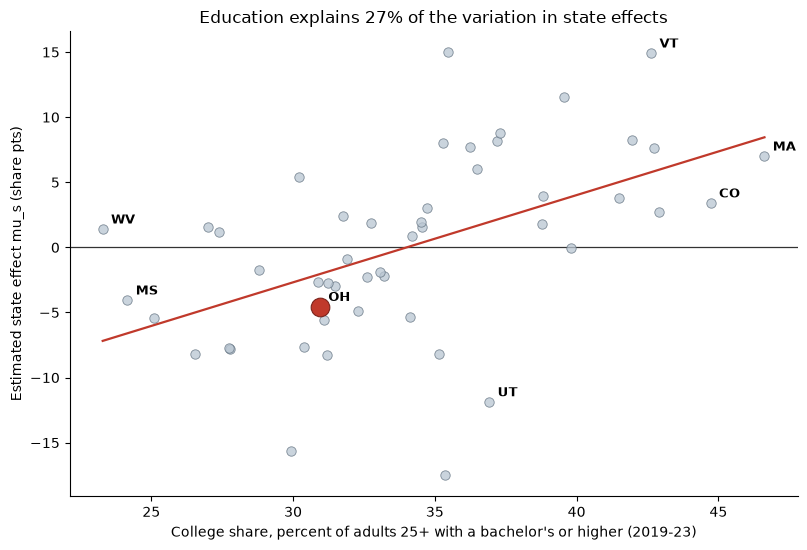

In [172]:
# =============================================================================
# EDUCATION: REPORT MATERIAL ONLY, NOT IN THE FORECAST
#
# The within-state change in college share was tried as a sixth term and came
# back at -0.0001 (se 0.0063, p = 0.99): once state fixed effects absorb the
# levels, every state credentials up at a similar rate and there is nothing
# left to fit. It is dropped from the specification and from the prediction.
#
# What education DOES explain is the cross-section of state effects:
#     mu_hat_s = c0 + c1*coll_s + e_s            N = 50
# This is descriptive. Dropping mu_s from the main model to put coll in levels
# would reopen the omitted-variable channel that moves the Brown premium, so
# the premium is never read off this regression.
# =============================================================================
DEMO = ROOT / 'raw' / 'demographics'      # ACS points at DEMO/acs5
edu_raw = pd.read_csv(DEMO / 'ers_education_1970_2023.csv', encoding='latin-1')

# State totals are already in the file as FIPS codes ending in 000 (Ohio =
# 39000), so no county aggregation is needed. 'State' is the postal code. The
# national row is FIPS 0, which also ends in 000, so drop it by its State code.
COLL_ATTR = "Percent of adults with a bachelor's degree or higher, 2019-23"
e = edu_raw[(edu_raw.Attribute == COLL_ATTR)
            & (edu_raw['FIPS Code'] % 1000 == 0)
            & (edu_raw.State != 'US')]
coll = e.set_index('State').Value          # coll_s, percent of adults 25+
assert set(races.state_po) <= set(coll.index), 'a state is missing education data'

sb = pd.DataFrame({'mu': mu.mu_s, 'coll': coll.reindex(mu.index)}).dropna()
specB = smf.ols('mu ~ coll', sb).fit()
print('--- Spec B: state effects on college share ---')
print(specB.summary2().tables[1].round(4).to_string())
print(f'R2 {specB.rsquared:.3f}   N {int(specB.nobs)}')
oh_fit = specB.predict({'coll': [sb.loc['OH', 'coll']]})[0]
print(f'\nOhio: coll = {sb.loc["OH", "coll"]:.1f} pct pts, '
      f'mu_OH = {sb.loc["OH", "mu"]:+.4f}, fitted {oh_fit:+.4f}, '
      f'residual {sb.loc["OH", "mu"] - oh_fit:+.4f}')

fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.scatter(sb.coll, sb.mu * 100, s=46, alpha=.75, facecolor='#b9c6d2',
           edgecolor='#5b6b7a', linewidth=.6, zorder=3)
ax.scatter([sb.loc['OH', 'coll']], [sb.loc['OH', 'mu'] * 100], s=180,
           facecolor='#c0392b', edgecolor='#7b241c', linewidth=.8, zorder=5)
xs = np.linspace(sb.coll.min(), sb.coll.max(), 50)
ax.plot(xs, specB.predict({'coll': xs}) * 100, color='#c0392b', lw=1.6, zorder=2)
for s in ['OH', 'MA', 'WV', 'CO', 'MS', 'VT', 'UT']:
    if s in sb.index:
        ax.annotate(s, (sb.loc[s, 'coll'], sb.loc[s, 'mu'] * 100), fontsize=9,
                    fontweight='bold', xytext=(6, 4), textcoords='offset points')
ax.axhline(0, color='#333', lw=.9, zorder=0)
ax.set(xlabel="College share, percent of adults 25+ with a bachelor's or higher (2019-23)",
       ylabel='Estimated state effect mu_s (share pts)',
       title=f'Education explains {specB.rsquared*100:.0f}% of the variation in state effects')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()



--- Husted counted as incumbent ---
  baseline (pres + Ohio effect)    +0.4390
  midterm penalty (R president)    +0.0330
  incumbency                       -0.0494
  Brown premium                    +0.0395
  = 2026 forecast                  0.4622   margin -7.6 pts

--- Husted counted as open seat ---
  baseline (pres + Ohio effect)    +0.4390
  midterm penalty (R president)    +0.0330
  incumbency                       +0.0000
  Brown premium                    +0.0395
  = 2026 forecast                  0.5115   margin +2.3 pts

Silver: 0.5177 two-party, margin +3.5 pts


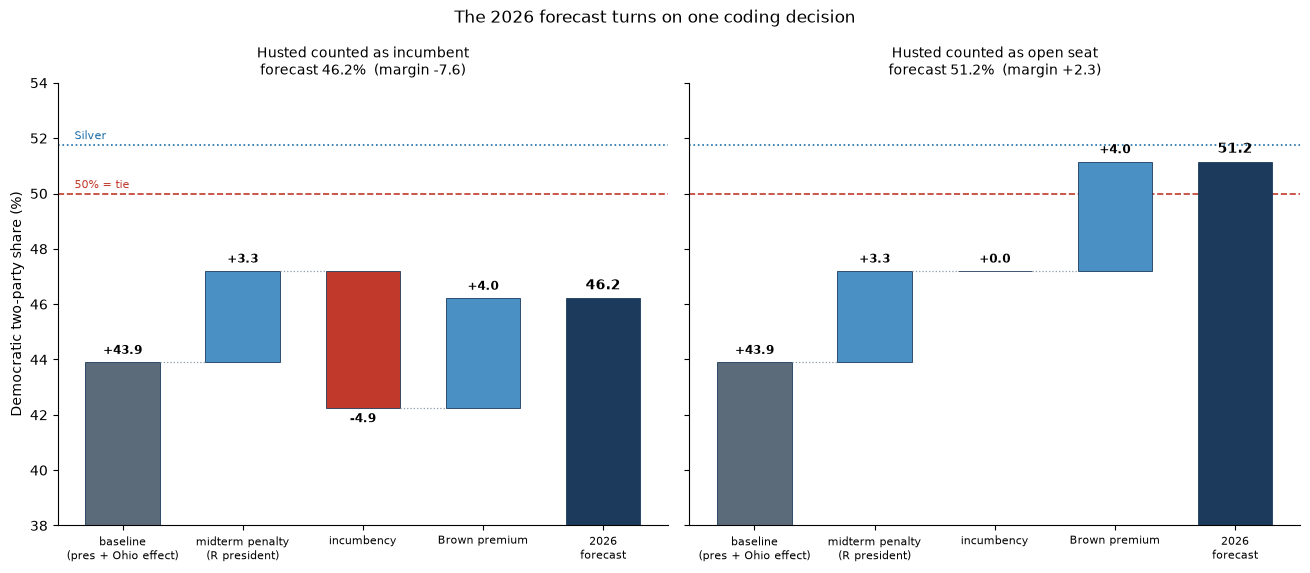

In [173]:
# =============================================================================
# THE 2026 PREDICTION UNDER TWO INCUMBENCY CODINGS
# Ohio two-party Dem share = baseline + midterm penalty + incumbency
#                            + Brown premium
# Education is deliberately absent: see the Spec B cell above for why.
# =============================================================================
PENALTY_2026 = -1      # Trump is president, and penalty is +1 for a DEM one

# Two codings of the same race, and the forecast turns on which you accept:
#   -1  Husted is a Republican incumbent: appointed to Vance's seat Jan 2025.
#    0  Husted is effectively an open-seat candidate: he was appointed, has
#       never faced Ohio voters statewide, and Brown has won three terms.
SCENARIOS = {'Husted counted as incumbent': -1,
             'Husted counted as open seat': 0}
SILVER = 0.4830 / (0.4830 + 0.4500)     # Silver 48.3 / 45.0 -> two-party share

def decompose(fit, inc_val):
    """Break the fitted 2026 value into the additive terms that produce it.
    Built from the RAW Ohio dummy so the arithmetic does not depend on which
    state statsmodels omitted as the reference, nor on how mu_s was centred."""
    b = fit.params
    return [('baseline\n(pres + Ohio effect)',
             b['Intercept'] + b['dem2p_pres'] * OH_PRES_2024
             + b.get('C(state_po)[T.OH]', 0.0)),
            ('midterm penalty\n(R president)', b['penalty'] * PENALTY_2026),
            ('incumbency', b['inc'] * inc_val),
            ('Brown premium', b['brown'])]

for sname, iv in SCENARIOS.items():
    parts = decompose(m_full, iv)
    tot = sum(v for _, v in parts)
    print(f'\n--- {sname} ---')
    for lab, v in parts:
        print(f'  {lab.replace(chr(10), " "):32s} {v:+.4f}')
    print(f'  {"= 2026 forecast":32s} {tot:.4f}'
          f'   margin {(2*tot-1)*100:+.1f} pts')
print(f'\nSilver: {SILVER:.4f} two-party, margin {(2*SILVER-1)*100:+.1f} pts')

# --- two waterfalls, one per incumbency coding -------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.8), sharey=True)
for ax, (sname, iv) in zip(axes, SCENARIOS.items()):
    parts = decompose(m_full, iv)
    labels = [p[0] for p in parts] + ['2026\nforecast']
    vals = [p[1] for p in parts]
    cum = np.cumsum(vals)
    starts = np.concatenate([[0], cum[:-1]])
    cols = ['#5b6b7a'] + ['#4a90c4' if v >= 0 else '#c0392b' for v in vals[1:]]
    for i, (st, v, c) in enumerate(zip(starts, vals, cols)):
        ax.bar(i, v * 100, bottom=st * 100, color=c, edgecolor='#1b3a5c',
               linewidth=.6, width=.62)
        ax.annotate(f'{v*100:+.1f}', (i, (st + v) * 100), ha='center',
                    va='bottom' if v >= 0 else 'top', fontsize=8.5,
                    fontweight='bold',
                    xytext=(0, 4 if v >= 0 else -4), textcoords='offset points')
        if i < len(vals) - 1:
            ax.plot([i + .31, i + 1 - .31], [cum[i] * 100] * 2, color='#8c9aa8',
                    lw=.9, ls=':')
    ax.bar(len(vals), cum[-1] * 100, color='#1b3a5c', edgecolor='#1b3a5c',
           linewidth=.6, width=.62)
    ax.annotate(f'{cum[-1]*100:.1f}', (len(vals), cum[-1] * 100), ha='center',
                va='bottom', fontsize=10, fontweight='bold',
                xytext=(0, 4), textcoords='offset points')
    ax.axhline(50, color='#c0392b', lw=1.2, ls='--', zorder=0)
    ax.axhline(SILVER * 100, color='#1b6ca8', lw=1.2, ls=':', zorder=0)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylim(38, 54)
    ax.set_title(f'{sname}\nforecast {cum[-1]*100:.1f}%  '
                 f'(margin {(2*cum[-1]-1)*100:+.1f})', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('Democratic two-party share (%)')
axes[0].annotate('50% = tie', (-0.4, 50), fontsize=8, color='#c0392b',
                 va='bottom', xytext=(0, 2), textcoords='offset points')
axes[0].annotate('Silver', (-0.4, SILVER * 100), fontsize=8, color='#1b6ca8',
                 va='bottom', xytext=(0, 2), textcoords='offset points')
fig.suptitle('The 2026 forecast turns on one coding decision', fontsize=12)
fig.tight_layout()
plt.show()


2024: Dem Senate share minus Dem presidential share, same state, same day
            sen   pres  runahead
state_po                        
MT        46.36  39.71      6.65
MN        58.12  52.17      5.95
HI        66.95  61.78      5.16
AZ        51.23  47.21      4.03
OH        48.13  44.34      3.78
RI        60.05  57.08      2.97
NY        59.20  56.34      2.86
TX        45.65  43.06      2.59
NV        50.87  48.42      2.45
MO        42.95  40.66      2.29
ND        33.48  31.30      2.18
NM        55.06  53.07      1.99
NJ        54.93  53.01      1.91
VA        54.48  52.95      1.53
DE        58.89  57.48      1.41
CT        58.44  57.38      1.06
MI        50.18  49.28      0.90
WI        50.43  49.56      0.87
PA        49.89  49.14      0.75
FL        43.50  43.39      0.12
WV        28.76  28.66      0.11
TN        34.87  34.94     -0.07
WA        59.25  59.46     -0.21
IN        39.80  40.35     -0.55
MS        37.19  38.43     -1.24
CA        58.87  60.40     -1.53
WY

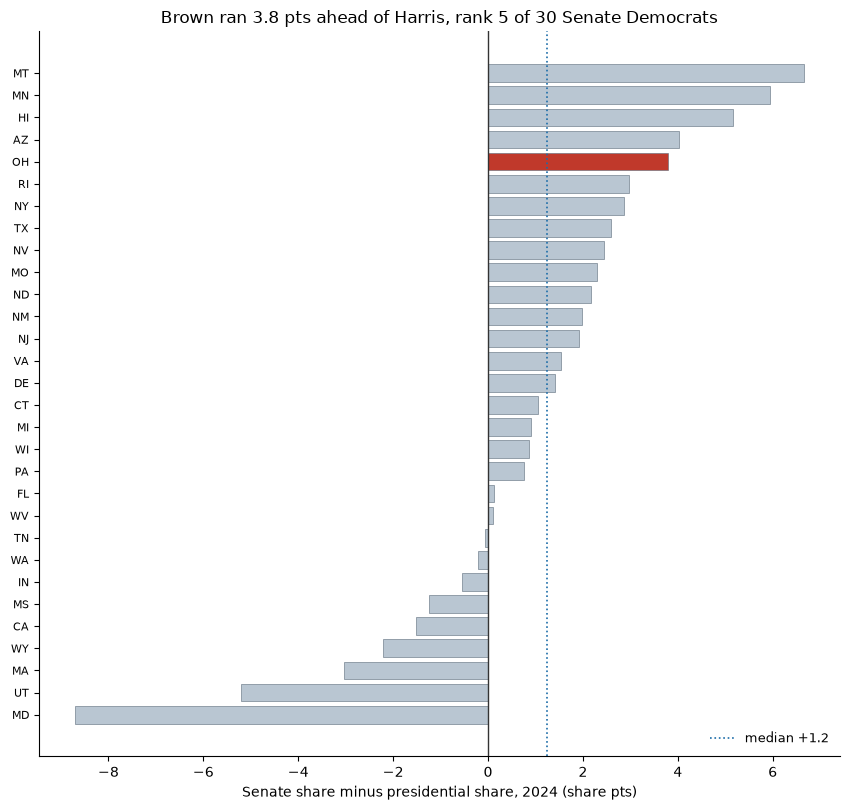

In [174]:
# =============================================================================
# A SECOND, CRUDER ESTIMATE OF THE BROWN PREMIUM: THE 2024 RUN-AHEAD
#
#   runahead_s = dem2p_senate_{s,2024} - dem2p_president_{s,2024}
#
# Same voters, same ballot, same day. Differencing the two offices within a
# state sweeps out everything common to them -- turnout, the national
# environment, state partisanship -- WITHOUT estimating anything. No
# regression, no fixed effects, no identifying assumption about other years.
#
# What it does NOT separate: Brown's personal appeal, his 2024 incumbency,
# and Bernie Moreno's weakness as a Republican candidate are all inside this
# one number. It is a ceiling on the personal premium, not a measurement.
# =============================================================================
MEDSL = ROOT / 'raw' / 'election_results' / 'senate_statewide'

def two_party_2024(df):
    """Statewide Dem two-party share in 2024, from MEDSL candidate-level rows."""
    d = df[(df.year == 2024) & df.party_simplified.isin(['DEMOCRAT', 'REPUBLICAN'])]
    g = d.groupby(['state_po', 'party_simplified']).candidatevotes.sum().unstack()
    return (g.DEMOCRAT / (g.DEMOCRAT + g.REPUBLICAN)).rename('dem2p')

pres24 = two_party_2024(pd.read_csv(MEDSL / 'medsl_1976-2024-president.csv'))
sen_all = pd.read_csv(MEDSL / 'medsl_1976-2024-senate-state.csv')
sen24 = two_party_2024(sen_all[~sen_all.special.fillna(False).astype(bool)])

ra = pd.DataFrame({'sen': sen24, 'pres': pres24}).dropna()
# Maine's "Democrat" two-party share is meaningless: Angus King is an
# independent and the Democrats did not field a serious candidate. Drop it.
ra = ra.drop(index='ME', errors='ignore')
ra['runahead'] = ra.sen - ra.pres
ra = ra.sort_values('runahead', ascending=False)

print('2024: Dem Senate share minus Dem presidential share, same state, same day')
print((ra * 100).round(2).to_string())
OH_RA = ra.loc['OH', 'runahead']
print(f'\nN = {len(ra)}   mean {ra.runahead.mean()*100:+.2f}   '
      f'median {ra.runahead.median()*100:+.2f}   sd {ra.runahead.std()*100:.2f}')
print(f'Ohio: {OH_RA*100:+.2f} share pts ({OH_RA*200:+.2f} margin pts), '
      f'rank {list(ra.index).index("OH") + 1} of {len(ra)}')
print(f'Brown above the median 2024 Dem Senate candidate: '
      f'{(OH_RA - ra.runahead.median())*100:+.2f} share pts')
print(f'\nFor comparison, the regression premium p was '
      f'{m_full.params["brown"]*100:+.2f} share pts (se {m_full.bse["brown"]*100:.2f}).')

fig, ax = plt.subplots(figsize=(8.6, 8.2))
cols = ['#c0392b' if s == 'OH' else '#b9c6d2' for s in ra.index]
y = np.arange(len(ra))[::-1]
ax.barh(y, ra.runahead * 100, color=cols, edgecolor='#5b6b7a', linewidth=.4)
ax.set_yticks(y)
ax.set_yticklabels(ra.index, fontsize=8)
ax.axvline(0, color='#333', lw=1)
ax.axvline(ra.runahead.median() * 100, color='#1b6ca8', lw=1.2, ls=':',
           label=f'median {ra.runahead.median()*100:+.1f}')
ax.set(xlabel='Senate share minus presidential share, 2024 (share pts)',
       title=f'Brown ran {OH_RA*100:.1f} pts ahead of Harris, rank '
             f'{list(ra.index).index("OH") + 1} of {len(ra)} Senate Democrats')
ax.legend(frameon=False, fontsize=9, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()
